In [1]:
from pathlib import Path

from maite_datasets.image_classification import MilitaryVehicles

data_root = Path(".")

# Downloads to ./data/militaryvehicles on first run (~100 MB). A re-run finds the files on disk.
MilitaryVehicles(root=data_root / "data", image_set="base", download=True)

/builds/jatic/aria/dataeval-flow/.nox/docs/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import warnings

import torch
import torchvision

(data_root / "trainers").mkdir(exist_ok=True)
(data_root / "models").mkdir(exist_ok=True)

onnx_path = data_root / "models" / "resnet18.onnx"
if not onnx_path.exists():
    resnet = torchvision.models.resnet18(weights="IMAGENET1K_V1").eval()
    resnet.fc = torch.nn.Identity()  # keep the 512 features, not ImageNet's 1,000 class scores
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # the exporter used here warns that a newer one is the default
        torch.onnx.export(
            resnet,
            (torch.zeros(1, 3, 224, 224),),
            str(onnx_path),
            input_names=["input"],
            output_names=["features"],
            dynamic_axes={"input": {0: "batch"}, "features": {0: "batch"}},  # any number of images at once
            dynamo=False,
        )

import onnxruntime

# Load it once here, so that a bad export fails now rather than in the middle of the run.
onnxruntime.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])

In [3]:
for name in ("train_fine", "test_fine"):
    folder = data_root / "data" / "militaryvehicles" / name
    print(f"{folder.relative_to(data_root)}: {sum(1 for _ in folder.rglob('*.jpg')):,} images")
print(f"{onnx_path.relative_to(data_root)}: {onnx_path.stat().st_size / 1e6:.0f} MB")

data/militaryvehicles/train_fine: 7,823 images
data/militaryvehicles/test_fine: 1,621 images
models/resnet18.onnx: 45 MB


In [4]:
%%writefile trainers/backbone.py
"""A frozen pretrained backbone with a nearest-centroid head.

The backbone's output (here ResNet-18's 512 features) is computed once per image; each training size refits only the
head, a mean feature row per class.
"""

from collections.abc import Mapping, Sequence
from pathlib import Path
from typing import Any

import numpy as np
from numpy.typing import NDArray

from dataeval_flow.evaluators.performance import Trainer, TrainerKit

# The data root: this file sits in its `trainers/` folder.
DATA_ROOT = Path(__file__).parents[1]
# ImageNet's channel means and deviations, on 0-255 pixels.
MEAN = np.array([123.675, 116.28, 103.53], dtype=np.float32)[:, None, None]
STD = np.array([58.395, 57.12, 57.375], dtype=np.float32)[:, None, None]


class Backbone:
    """The pretrained model's outputs for each item, computed once and kept by dataset and index."""

    def __init__(self, weights: str, size: int) -> None:
        self.weights = DATA_ROOT / weights
        self.size = size
        self.session: Any = None
        self.cache: dict[tuple[int, int], NDArray[np.float32]] = {}

    def __call__(self, dataset: Any, indices: Sequence[int]) -> NDArray[np.float32]:
        """The features of the items at `indices`, one row each."""
        missing = sorted({index for index in indices if (id(dataset), index) not in self.cache})
        for start in range(0, len(missing), 64):
            batch = missing[start : start + 64]
            scores = self._run(np.stack([self._prepare(dataset[index][0]) for index in batch]))
            self.cache.update({(id(dataset), index): row for index, row in zip(batch, scores, strict=True)})
        return np.stack([self.cache[id(dataset), index] for index in indices])

    def _prepare(self, image: Any) -> NDArray[np.float32]:
        pixels = np.asarray(image, dtype=np.float32)
        rows = np.linspace(0, pixels.shape[1] - 1, self.size).astype(int)
        cols = np.linspace(0, pixels.shape[2] - 1, self.size).astype(int)
        return (pixels[:, rows][:, :, cols] - MEAN) / STD

    def _run(self, batch: NDArray[np.float32]) -> NDArray[np.float32]:
        if self.session is None:
            import onnxruntime
            from dataeval.config import get_device

            gpu = get_device().type == "cuda"
            providers = ["CUDAExecutionProvider", "CPUExecutionProvider"] if gpu else ["CPUExecutionProvider"]
            self.session = onnxruntime.InferenceSession(str(self.weights), providers=providers)
        return self.session.run(None, {self.session.get_inputs()[0].name: batch})[0]


class Centroids:
    """The head: one mean feature row per class seen in training."""

    def __init__(self) -> None:
        self.labels = np.empty(0, dtype=int)
        self.means = np.empty((0, 0), dtype=np.float32)


class Fit:
    """Refit the head on the items at `indices`; an index may repeat, as DataEval draws with replacement."""

    def __init__(self, backbone: Backbone) -> None:
        self.backbone = backbone

    def train(self, model: Centroids, dataset: Any, indices: Sequence[int]) -> None:
        """Average each class's features."""
        features = self.backbone(dataset, indices)
        labels = np.array([int(np.argmax(dataset[index][1])) for index in indices])
        model.labels = np.unique(labels)
        model.means = np.stack([features[labels == label].mean(axis=0) for label in model.labels])


class Score:
    """The share of the test set whose nearest centroid is its own class."""

    def __init__(self, backbone: Backbone) -> None:
        self.backbone = backbone

    def evaluate(self, model: Centroids, dataset: Any) -> Mapping[str, float]:
        """Accuracy, from 0 to 1."""
        indices = list(range(len(dataset)))
        features = self.backbone(dataset, indices)
        distances = ((features[:, None, :] - model.means[None]) ** 2).sum(axis=2)
        labels = np.array([int(np.argmax(dataset[index][1])) for index in indices])
        return {"accuracy": float(np.mean(model.labels[np.argmin(distances, axis=1)] == labels))}


class BackboneTrainer(Trainer):
    """Nearest centroids over a frozen ONNX model's features; `weights` is relative to the data root."""

    def __init__(self, weights: str, size: int = 224) -> None:
        self.weights = weights
        self.size = size

    def build(self) -> TrainerKit:
        """An empty head, refit at each size; a deep copy resets it. The backbone is loaded on first use."""
        backbone = Backbone(self.weights, self.size)
        return TrainerKit(model=Centroids(), training_strategy=Fit(backbone), evaluation_strategy=Score(backbone))

Writing trainers/backbone.py


In [5]:
print(Path("measure_data_sufficiency.yaml").read_text())

# Mirrors the configuration in measure_data_sufficiency.py
# All paths are relative to the data root (docs/source/notebooks/)
#
# You can execute this workflow with `dataeval-flow --config measure_data_sufficiency.yaml --output ./output`,
# once the notebook has put the model under models/ and the trainer under trainers/.
#
# yaml-language-server: $schema=../../../config/params.schema.json

datasets:
  - {name: vehicles_train, format: image_folder, path: data/militaryvehicles/train_fine, infer_labels: true}
  - {name: vehicles_test, format: image_folder, path: data/militaryvehicles/test_fine, infer_labels: true}

sources:
  - {name: train, dataset: vehicles_train}
  - {name: test, dataset: vehicles_test}

evaluators:
  - name: sufficiency
    type: sufficiency
    schedule: [100, 300, 800, 1600, 3200]
    trainer:
      path: trainers/backbone.py
      class: BackboneTrainer
      params: {weights: models/resnet18.onnx}

workflows:
  - name: how_much_data
    inputs: [train, test]
    

In [6]:
import logging
import sys
import warnings

from dataeval_flow import ExperimentalWarning, load_config, run_task, set_device

set_device("cpu")  # the same numbers on a machine with a GPU
warnings.simplefilter("ignore", ExperimentalWarning)  # the warning the note at the top describes

progress = logging.getLogger("dataeval_flow.evaluators.performance")
progress.addHandler(logging.StreamHandler(sys.stdout))
progress.setLevel(logging.INFO)

config = load_config("measure_data_sufficiency.yaml")
result = run_task(config, "sufficiency", data_dir=data_root)

Sufficiency 1/5: run 1 of 1, 100 items, accuracy=0.1444


Sufficiency 2/5: run 1 of 1, 300 items, accuracy=0.2079


Sufficiency 3/5: run 1 of 1, 800 items, accuracy=0.269


Sufficiency 4/5: run 1 of 1, 1600 items, accuracy=0.2727


Sufficiency 5/5: run 1 of 1, 3200 items, accuracy=0.2813


In [7]:
assert result.success, result.errors

In [8]:
print(result.report())


  HOW_MUCH_DATA
  Workflow:  how_much_data (custom workflow)
  Timestamp: 2026-11-07T08:46:43.453849+00:00
  Duration:  58.48s
  Source:    train (vehicles_train)
             test (vehicles_test)

  Steps: 2 ran

  SUMMARY
  Performance Sufficiency ........ 1 of 4 targets reached at 3,200 items  [!!]

  Health: 1 warning(s) [!!] — review flagged findings

  PERFORMANCE SUFFICIENCY                  1 of 4 targets reached at 3,200 items
  Items  accuracy
  -----  --------  ------------------------------
    100    0.1444  ████████████▍
    300    0.2079  █████████████████▉
    800    0.2690  ███████████████████████
  1,600    0.2727  ███████████████████████▍
  3,200    0.2813  ████████████████████████▏
  target                            (0.27)|-----|(0.35)

  Target           Reached  Fitted curve reaches it at
  ---------------  -------  -----------------------------
  accuracy ≥ 0.27      yes
  accuracy ≥ 0.29       no  ~4,453 items (1.4x)
  accuracy ≥ 0.3        no  ~13,193 items (

In [9]:
for finding in result.findings:
    print(f"{finding.severity:<8} {finding.title:<24} {finding.brief}")

warning  Performance Sufficiency  1 of 4 targets reached at 3,200 items


In [10]:
# The page styles its whole document, so the docs show it in an iframe of its own rather than
# letting its stylesheet restyle this site. Readers don't need this to use `to_html()`.
import html

from IPython.display import display


def show(page: str, height: int = 640) -> None:
    """*page* in an iframe, so its stylesheet and script stay inside it."""
    frame = (
        f'<iframe srcdoc="{html.escape(page, quote=True)}" title="HTML report" loading="lazy" '
        f'style="width:100%;height:{height}px;border:1px solid #d1d9e0;border-radius:6px"></iframe>'
    )
    display({"text/html": frame}, raw=True)

In [11]:
show(result.to_html())

<iframe srcdoc="<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>how_much_data</title>
<style>:root { color-scheme: light dark;
 --bg: #ffffff; --card: #ffffff; --soft: #f6f8fa; --ink: #111827; --muted: #6b7280; --rule: #e5e7eb;
 --link: #1d4ed8; --ok: #16a34a; --info: #2563eb; --warning: #d97706; --mark: #dc2626;
 --s0: #2563eb; --s1: #d97706; --s2: #7c3aed; --s3: #16a34a;
 --tag: #eef2ff; --tag-ink: #1e1b4b;
}
@media (prefers-color-scheme: dark) { :root {
 --bg: #0f1115; --card: #171a21; --soft: #1d212a; --ink: #e5e7eb; --muted: #9ca3af; --rule: #2a2f3a;
 --link: #93c5fd; --ok: #22c55e; --info: #60a5fa; --warning: #f59e0b; --mark: #f87171;
 --s0: #60a5fa; --s1: #f59e0b; --s2: #a78bfa; --s3: #22c55e;
 --tag: #232a3d; --tag-ink: #c7d2fe;
} }
body { margin: 0; color: var(--ink); background: var(--bg);
 font: 15px/1.5 system-ui, -apple-system, "Segoe UI", Roboto, "Helvetica Neue", Arial, sans-serif; }
main { max-width: 72rem; margin: 0 auto; padding: 1.5rem; }
a { color: var(--link); }
h1, h2, h3, h4 { margin: 1.25rem 0 0.5rem; line-height: 1.25; }
h1 { font-size: 1.6rem; } h2 { font-size: 1.2rem; } h3 { font-size: 1.05rem; } h4 { font-size: 0.95rem; }
nav.contents { border: 1px solid var(--rule); border-radius: 7px; padding: 0.25rem 1rem; margin-bottom: 1.5rem; }
nav.contents h2 { font-size: 1rem; margin: 0.5rem 0; }
.controls { display: flex; justify-content: flex-end; gap: 0.5rem; margin-bottom: 0.5rem; }
.controls button { font: inherit; font-size: 0.8rem; padding: 0.2rem 0.7rem; cursor: pointer;
 color: var(--ink); background: var(--soft); border: 1px solid var(--rule); border-radius: 4px; }
.report { margin-bottom: 2.5rem; }
.report-head { display: flex; align-items: baseline; gap: 0.75rem; flex-wrap: wrap;
 border-bottom: 2px solid var(--ink); padding-bottom: 0.3rem; }
.report-head h1 { margin: 0; }
dl.fields.provenance { display: grid; grid-template-columns: max-content 1fr; gap: 0.15rem 1rem;
 margin: 0.6rem 0 1.2rem; padding: 0.5rem 0.8rem; background: var(--soft); border-radius: 6px;
 color: var(--muted); font-size: 0.85rem; }
dl.provenance dt { font-weight: 600; color: var(--ink); }
dl.provenance dd { margin: 0; overflow-wrap: anywhere; }
section.section > h2 { border-bottom: 1px solid var(--rule); padding-bottom: 0.2rem; }
details.card, details.panel { background: var(--card); border: 1px solid var(--rule);
 border-left: 4px solid var(--info); border-radius: 7px; padding: 0.3rem 1rem 0.6rem; margin: 0.9rem 0; }
details.card.ok { border-left-color: var(--ok); } details.card.warning { border-left-color: var(--warning); }
details.panel { border-left-color: var(--rule); margin-top: 1.5rem; }
:is(details.card, details.panel) > summary { cursor: pointer; list-style: none; }
:is(details.card, details.panel) > summary::-webkit-details-marker { display: none; }
:is(details.card, details.panel) > summary h2 { display: inline; font-size: 1.1rem; margin: 0; }
:is(details.card, details.panel) > summary::before { content: "▸"; color: var(--muted); margin-right: 0.4rem; }
:is(details.card, details.panel)[open] > summary::before { content: "▾"; }
.brief { font-weight: normal; color: var(--muted); margin-left: 0.5rem; }
.badge { font-size: 0.72rem; font-weight: 700; letter-spacing: 0.02em; border-radius: 1rem; padding: 0.05rem 0.55rem;
 margin-left: 0.5rem; color: #fff; background: var(--info); vertical-align: middle; }
.badge.ok { background: var(--ok); } .badge.warning { background: var(--warning); }
.badge.failed { background: var(--mark); }
code, pre { font-family: ui-monospace, SFMono-Regular, Menlo, Consolas, "DejaVu Sans Mono", monospace; }
code { font-size: 0.9em; background: var(--soft); padding: 0 0.2em; border-radius: 3px; }
pre { background: var(--soft); padding: 0.75rem; overflow-x: auto; font-size: 0.85rem; }
pre code { background: none; padding: 0; }
table { border-collapse: collapse; margin: 0.5rem 0; font-size: 0.85rem; font-va

In [12]:
output = result.steps["measured"].output
print("sizes:   ", output.steps.tolist())
print("accuracy:", [round(float(value), 4) for value in output.averaged_measures["accuracy"]])
print(f"training set: {len(result.sources['train']):,} items; test set: {len(result.sources['test']):,}")

sizes:    [100, 300, 800, 1600, 3200]
accuracy: [0.1444, 0.2079, 0.269, 0.2727, 0.2813]
training set: 7,823 items; test set: 1,621


In [13]:
scale, exponent, asymptote = output.params["accuracy"]
print(f"1 - accuracy = {scale:.3f} * items ** -{exponent:.3f} + {asymptote:.3f}")
print(f"The curve levels off near {1 - asymptote:.3f}\n")
print(output.project([3_200, 7_823, 20_000]))

1 - accuracy = 1.951 * items ** -0.529 + 0.687
The curve levels off near 0.313

shape: (3, 2)
┌───────┬──────────┐
│ step  ┆ accuracy │
│ ---   ┆ ---      │
│ i64   ┆ f64      │
╞═══════╪══════════╡
│ 3200  ┆ 0.285631 │
│ 7823  ┆ 0.295899 │
│ 20000 ┆ 0.302544 │
└───────┴──────────┘


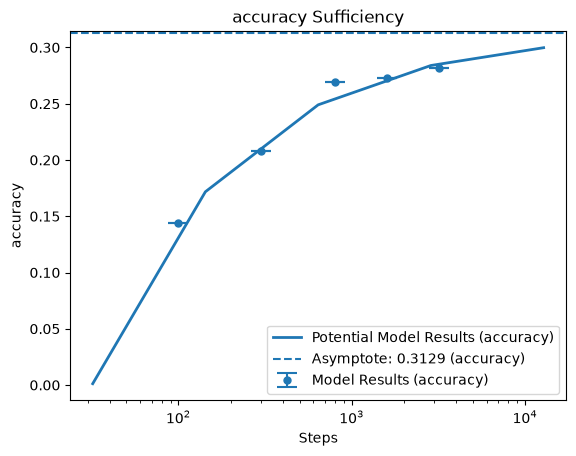

In [14]:
from dataeval_plots import plot

_ = plot(output)

In [15]:
extras = result.to_dict()["steps"]["measured"]["output"]["extras"]
print(extras["trainer"])
print(extras["params"])

{'path': 'trainers/backbone.py', 'class': 'BackboneTrainer', 'sha256': 'a5d9474160323e0e81c10563b3f0b5264805abe485eba88750e37188f32f1a0b'}
{'accuracy': [1.9510163790808213, 0.5292316084037102, 0.6871275333915815]}
